# Week 5 · Class 1 — Probability & Distributions in Python 🎲⌚

**90 min · hands-on** · tools: `numpy`, `pandas`, `matplotlib`, `scipy.stats`

This notebook is the practical side of today's slides. The big idea: **if you can simulate it, you can understand it.**
Every formula from the lecture gets checked twice: once with a **simulation** and once on **real-looking wearable data** (the `wearables_daily.csv` file from Week 3).

| Part | Time | What we do |
|---|---|---|
| 0 | 3' | Setup |
| 1 | 12' | Probability = long-run frequency (simulating dice) |
| 2 | 8' | Probabilities from data: events are boolean masks |
| 3 | 12' | Conditional probability: does short sleep raise stress? |
| 4 | 12' | Bayes: the smartwatch AFib alert |
| 5 | 12' | Expected value and variance |
| 6 | 10' | Why the sample variance divides by n − 1 |
| 7 | 15' | Distributions with `scipy.stats` |
| 8 | 6' | Final challenge + recap |

🧑‍💻 = we write it **together** · ✋ **Your turn** = 2–3 minutes on your own, then we compare.

### 📂 Dataset used in this notebook
| | |
|---|---|
| **File** | `wearables_daily.csv` (the same file as in Week 3, Class 2) |
| **Size** | 250 users × 365 days = **91,250 rows**, 17 columns |
| **Columns we use** | `steps`, `sleep_hours`, `resting_hr`, `stress_score`, `device`, `date` |
| **Used in** | Parts 2, 3, 4 (last exercise), 6 and 7 |
| **Not needed in** | Parts 1, 4 (AFib), 5 and 8: there we **simulate** random numbers with numpy |

Each row is **one user-day** from a wearable device: daily steps, sleep, resting heart rate and a stress score.

## 0 · Setup ⚙️

📁 **Before running:** put `wearables_daily.csv` next to this notebook.
- **Colab:** click the folder icon on the left and drag the file in (it is deleted when the session ends, so upload it again next time).
- **VS Code / Jupyter:** keep it in the same folder as the notebook, or change the path in `pd.read_csv(...)` below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

rng = np.random.default_rng(42)    # our random number generator; 42 = seed → same results every run

In [2]:
df = pd.read_csv("wearables_daily.csv", parse_dates=["date"])
print(df.shape)
df[["user_id", "date", "steps", "sleep_hours", "resting_hr", "stress_score"]].head()

(91250, 17)


,user_id,date,steps,sleep_hours,resting_hr,stress_score
0,U001,2025-10-01,11208,6.24,68.0,56.0
1,U001,2025-10-02,14360,5.86,65.0,56.0
2,U001,2025-10-03,10323,6.95,65.0,56.0
3,U001,2025-10-04,10048,7.06,65.0,41.0
4,U001,2025-10-05,10675,6.76,64.0,59.0


> 💡 **Why a seed?** Random numbers in a computer are generated by an algorithm. Fixing the *seed* means everyone in the room gets exactly the same "random" numbers, so we can compare results.

---
## 1 · Probability = long-run frequency 🎲 (12')

Slides: *P(A) ≈ the fraction of times A happens if we repeat the experiment many times.*
Let's roll a die **10 times**, then **100,000 times**.

In [3]:
rolls = rng.integers(1, 7, size=10)     # integers from 1 to 6 (the 7 is NOT included)
print(rolls)

[1 5 4 3 3 6 1 5 2 1]


In [4]:
rolls = rng.integers(1, 7, size=100_000)

is_even = rolls % 2 == 0          # a boolean array: True where the roll is even
print("first rolls:", rolls[:8])
print("is even?   :", is_even[:8])
print("P(even) ≈", is_even.mean())  # mean of True/False = fraction of True

first rolls: [4 6 5 5 5 5 4 1]
is even?   : [ True  True False False False False  True False]
P(even) ≈ 0.49965


⭐ **Trick to remember:** the mean of a boolean array is the **fraction of `True`**. We will use this all day: `mask.mean()` = estimated probability.

Now let's **watch** the frequency settle down as we roll more and more.

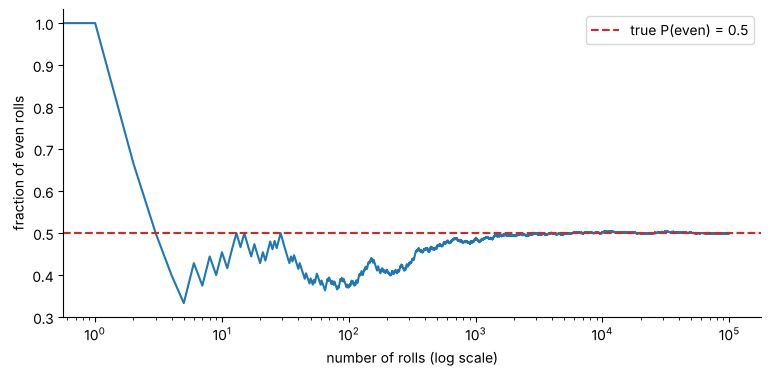

In [5]:
running_freq = np.cumsum(is_even) / np.arange(1, len(is_even) + 1)   # fraction of evens after 1, 2, 3, ... rolls

plt.plot(running_freq, color="tab:blue")
plt.axhline(0.5, color="tab:red", ls="--", label="true P(even) = 0.5")
plt.xscale("log")
plt.xlabel("number of rolls (log scale)"); plt.ylabel("fraction of even rolls")
plt.legend(); plt.show()

With few rolls the frequency jumps around; with many rolls it gets close to 0.5. This is the **law of large numbers**.

### Two dice: exact answer vs simulation
Sample space Ω = all 36 pairs (die 1, die 2). All equally likely → **P(A) = favourable / possible**.

In [6]:
# Exact: list the whole sample space
omega = [(a, b) for a in range(1, 7) for b in range(1, 7)]
print(len(omega), "outcomes, e.g.", omega[:4])

favourable = [pair for pair in omega if sum(pair) == 7]
print("pairs with sum 7:", favourable)
print("exact P(sum = 7) =", len(favourable), "/ 36 =", round(len(favourable) / 36, 4))

36 outcomes, e.g. [(1, 1), (1, 2), (1, 3), (1, 4)]
pairs with sum 7: [(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)]
exact P(sum = 7) = 6 / 36 = 0.1667


🧑‍💻 **Code with me:** estimate P(sum = 7) by simulating 100,000 throws of two dice.

In [7]:
die1 = rng.integers(1, 7, size=100_000)
die2 = rng.integers(1, 7, size=100_000)
total = die1 + die2

print("simulated P(sum = 7) ≈", (total == 7).mean())

simulated P(sum = 7) ≈ 0.16398


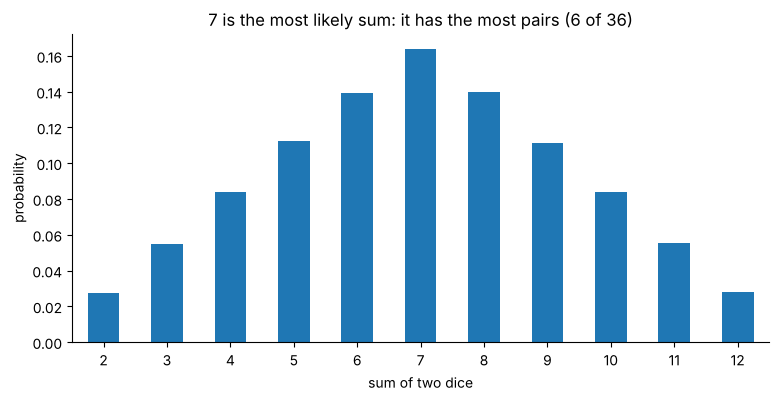

In [8]:
# The whole distribution of the sum: 2 ... 12
freq = pd.Series(total).value_counts(normalize=True).sort_index()   # normalize=True → fractions instead of counts
freq.plot(kind="bar", color="tab:blue")
plt.xlabel("sum of two dice"); plt.ylabel("probability"); plt.xticks(rotation=0)
plt.title("7 is the most likely sum: it has the most pairs (6 of 36)"); plt.show()

### Check the rules from the slides
- **Complement:** P(not A) = 1 − P(A)
- **Union:** P(A or B) = P(A) + P(B) − P(A and B)

With numpy masks: **or** = `|`, **and** = `&`, **not** = `~` (always use brackets around each condition!).

In [9]:
A = total >= 10          # A: sum is at least 10
B = die1 == die2         # B: a double (1-1, 2-2, ...)

print("P(not A)        :", (~A).mean(), " vs 1 − P(A):", 1 - A.mean())
print("P(A or B)       :", (A | B).mean())
print("P(A)+P(B)−P(A&B):", A.mean() + B.mean() - (A & B).mean())

P(not A)        : 0.83314  vs 1 − P(A): 0.83314
P(A or B)       : 0.27951
P(A)+P(B)−P(A&B): 0.27951


✋ **Your turn (2'):** estimate the probability that **at least one** of the two dice shows a 6.
*Hint:* use `|`. Then check with the complement: 1 − P(no 6 at all) = 1 − (5/6)².

In [10]:
at_least_one_six = (die1 == 6) | (die2 == 6)
print("simulated:", at_least_one_six.mean())
print("exact    :", 1 - (5 / 6) ** 2)

simulated: 0.30479
exact    : 0.30555555555555547


---
## 2 · Probabilities from data: events are boolean masks ⌚ (8')

In real life we don't know the true probabilities: we **estimate** them from data, exactly like with the dice.
Each row of our dataset is one **user-day**. An *event* is a condition on a row, e.g. "the user walked at least 10,000 steps".

First, a tiny bit of cleaning (we found these issues in Week 3): sensor glitches in `steps` and missing sleep values.

In [11]:
data = df[df["steps"] < 60_000].dropna(subset=["sleep_hours"]).copy()
print(f"kept {len(data):,} of {len(df):,} rows")

kept 88,456 of 91,250 rows


In [12]:
goal = data["steps"] >= 10_000            # event: hit the step goal
short_sleep = data["sleep_hours"] < 6      # event: slept less than 6 hours
high_stress = data["stress_score"] >= 60   # event: high stress score

print("P(goal)        ≈", round(goal.mean(), 3))
print("P(short sleep) ≈", round(short_sleep.mean(), 3))
print("P(high stress) ≈", round(high_stress.mean(), 3))

P(goal)        ≈

 0.259
P(short sleep) ≈ 0.063
P(high stress) ≈ 0.217


🧑‍💻 **Code with me:** P(short sleep **and** high stress) and P(short sleep **or** high stress). Check the union rule on real data.

In [13]:
p_and = (short_sleep & high_stress).mean()
p_or = (short_sleep | high_stress).mean()

print("P(short and stressed) ≈", round(p_and, 4))
print("P(short or stressed)  ≈", round(p_or, 4))
print("union rule            =", round(short_sleep.mean() + high_stress.mean() - p_and, 4))

P(short and stressed) ≈ 0.0348
P(short or stressed)  ≈ 0.2446


union rule            = 0.2446


---
## 3 · Conditional probability: does short sleep raise stress? 😴➡️😰 (12')

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}$$

In words: **keep only the rows where B happened**, then compute how often A happens there.

In [14]:
# Way 1: filter the rows, then take the fraction
p_stress_given_short = high_stress[short_sleep].mean()      # only rows where short_sleep is True
p_stress_given_normal = high_stress[~short_sleep].mean()

print("P(high stress)                ≈", round(high_stress.mean(), 3))
print("P(high stress | short sleep)  ≈", round(p_stress_given_short, 3))
print("P(high stress | normal sleep) ≈", round(p_stress_given_normal, 3))

P(high stress)                ≈ 0.217
P(high stress | short sleep)  ≈ 0.556
P(high stress | normal sleep) ≈ 0.194


In [15]:
# Way 2: the formula P(A and B) / P(B) gives the same number
print(round((high_stress & short_sleep).mean() / short_sleep.mean(), 3))

0.556


### Way 3: `pd.crosstab` — the table from the slides in one line
`normalize="index"` divides every row by its total → each row becomes a **conditional** distribution.

In [16]:
table = pd.crosstab(short_sleep.rename("short sleep"), high_stress.rename("high stress"), margins=True)
table

high stress,False,True,All
short sleep,,,
False,66824,16090,82914
True,2462,3080,5542
All,69286,19170,88456


In [17]:
pd.crosstab(short_sleep.rename("short sleep"), high_stress.rename("high stress"), normalize="index").round(3)

high stress,False,True
short sleep,,
False,0.806,0.194
True,0.444,0.556


📌 **Reading:** after a short night, the chance of a high-stress day is about **3 times** higher than after a normal night.

**Independence check:** A and B are independent if P(A | B) = P(A). Here 0.56 ≠ 0.22 → sleep and stress are **dependent**.

> ⚠️ Dependent ≠ causal. Maybe stressed people sleep badly, or a third factor (a deadline!) causes both. Probability only tells us they move together.

✋ **Your turn (3'):**
1. Compute P(hit step goal | device) for every device. Hint: `data.groupby("device")` and the mean of a boolean column.
2. Is hitting the goal independent of the device?

In [18]:
data["goal"] = goal
print("P(goal) overall:", round(data["goal"].mean(), 3))
data.groupby("device")["goal"].mean().round(3).sort_values()

P(goal) overall: 0.259


device
Apple Watch    0.238
Withings       0.257
Fitbit         0.269
Garmin         0.273
Name: goal, dtype: float64

*Answer:* if goal and device were independent, every device would give the overall P(goal) ≈ 0.26. Garmin users hit it about 27% of the time and Apple Watch users about 24%: a small gap, but with 20,000+ days per device it is probably not just noise. Thursday we learn how to **test** that properly.

---
## 4 · Bayes: the smartwatch AFib alert ❤️⌚ (12')

$$P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)}, \qquad P(B) = P(B\mid A)P(A) + P(B \mid A^c)P(A^c)$$

From the slides: 2% of users over 65 have AFib, the watch detects it 95% of the time, and gives a false alarm to 5% of healthy users.

🧑‍💻 **Code with me:** a function we can reuse for any test.

In [19]:
def posterior(prior, sensitivity, false_positive_rate):
    # P(condition | positive test) with Bayes' theorem
    p_positive = sensitivity * prior + false_positive_rate * (1 - prior)   # total probability of an alert
    return sensitivity * prior / p_positive

print(f"P(AF | alert) = {posterior(0.02, 0.95, 0.05):.3f}")

P(AF | alert) = 0.279


Don't trust the formula? **Simulate 100,000 users** and count, exactly like the tree on the slide.

In [20]:
n_users = 100_000
has_af = rng.random(n_users) < 0.02                  # rng.random() gives numbers in [0, 1): True with prob 0.02

alert = np.where(has_af,
                 rng.random(n_users) < 0.95,         # if AF: alert with prob 0.95
                 rng.random(n_users) < 0.05)         # if no AF: false alarm with prob 0.05

print("users with AF   :", has_af.sum())
print("alerts          :", alert.sum())
print("real AF / alerts:", round(has_af[alert].mean(), 3))

users with AF   : 1941
alerts          : 6740
real AF / alerts: 0.274


### The prior matters: how does P(AF | alert) change with how common AF is?

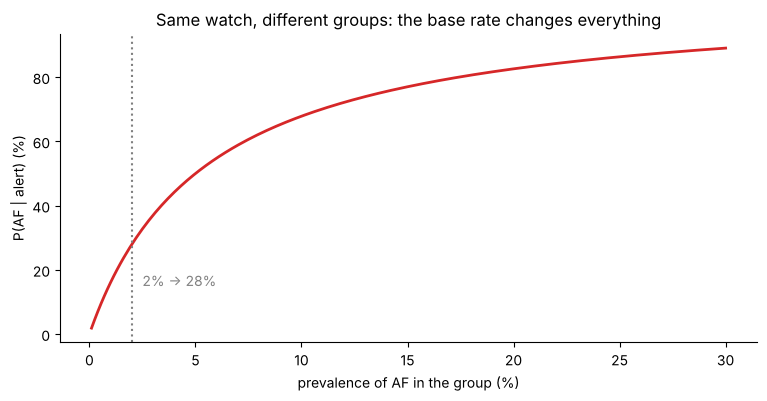

In [21]:
priors = np.linspace(0.001, 0.30, 200)
plt.plot(priors * 100, posterior(priors, 0.95, 0.05) * 100, color="tab:red", lw=2)
plt.axvline(2, color="grey", ls=":")
plt.text(2.5, 15, "2% → 28%", color="grey")
plt.xlabel("prevalence of AF in the group (%)"); plt.ylabel("P(AF | alert) (%)")
plt.title("Same watch, different groups: the base rate changes everything"); plt.show()

### Updating twice
After one alert, your belief went from 2% to 28%. That **posterior becomes the new prior**. What if a second, independent check also alerts?

In [22]:
after_one = posterior(0.02, 0.95, 0.05)
after_two = posterior(after_one, 0.95, 0.05)
print(f"after 1 alert: {after_one:.2f} · after 2 alerts: {after_two:.2f}")

after 1 alert: 0.28 · after 2 alerts: 0.88


✋ **Your turn (3'):** use Bayes on our wearable data. Compute **P(short sleep | high stress)** in two ways:
1. directly by filtering the rows,
2. with Bayes from P(high stress | short sleep), P(short sleep) and P(high stress).

In [23]:
direct = short_sleep[high_stress].mean()
bayes = p_stress_given_short * short_sleep.mean() / high_stress.mean()
print(round(direct, 4), round(bayes, 4))

0.1607 0.1607


---
## 5 · Expected value and variance 🎯 (12')

For a random variable X with values x and probabilities P(X = x):

$$\mathrm{E}[X] = \mu = \sum_x x\,P(X=x) \qquad \mathrm{Var}(X) = \sum_x (x-\mu)^2\,P(X=x) \qquad \sigma = \sqrt{\mathrm{Var}(X)}$$

In [24]:
x = np.array([1, 2, 3, 4, 5, 6])
p = np.full(6, 1 / 6)               # six times 1/6

mu = np.sum(x * p)                  # probability-weighted average
var = np.sum((x - mu) ** 2 * p)     # weighted average of squared distances
print(f"E[X] = {mu:.3f}   Var(X) = {var:.3f}   σ = {np.sqrt(var):.3f}")

E[X] = 3.500   Var(X) = 2.917   σ = 1.708


In [25]:
# Check with a simulation: long-run average and spread of many rolls
many = rng.integers(1, 7, size=1_000_000)
print(f"simulated mean = {many.mean():.3f}   simulated var = {many.var():.3f}")

simulated mean = 3.499   simulated var = 2.915


### Is the game worth it?
You pay 2 €, roll a die, and win 6 € only if you roll a 6. The expected value tells us what happens **on average over many games**.

In [26]:
gain = np.where(many == 6, 6, 0) - 2       # win 6 € on a six, minus the 2 € ticket
print("average gain per game:", gain.mean().round(3), "€   (theory: −1 €)")
print("after 1,000,000 games you have lost about", int(-gain.sum()), "€")

average gain per game: -1.001 €   (theory: −1 €)
after 1,000,000 games you have lost about 1001234 €


🧑‍💻 **Code with me:** a **loaded die** that shows 6 half of the time and every other face with probability 0.1. Compute E[X] and Var(X). Is it riskier than a fair die?

In [27]:
p_loaded = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.5])
print("probabilities sum to", p_loaded.sum())   # always check: must be 1!

mu_l = np.sum(x * p_loaded)
var_l = np.sum((x - mu_l) ** 2 * p_loaded)
print(f"loaded die: E[X] = {mu_l:.2f}, σ = {np.sqrt(var_l):.2f}   (fair die: 3.50 and 1.71)")

probabilities sum to 1.0
loaded die: E[X] = 4.50, σ = 1.80   (fair die: 3.50 and 1.71)


### Shortcut you will see in books
$$\mathrm{Var}(X) = \mathrm{E}[X^2] - \mu^2$$

In [28]:
print(np.sum(x**2 * p) - mu**2, "=", var)

2.916666666666666 = 2.9166666666666665


---
## 6 · Why the sample variance divides by n − 1 🔍 (10')

Let's play God: we treat **all 88,000 resting heart rates** in our data as the **population**. We know the true variance σ².
Then we pretend to be a researcher who only sees a **small sample of n = 5** and estimates σ² from it. We repeat that 20,000 times.

In [29]:
population = data["resting_hr"].to_numpy()
sigma2 = population.var(ddof=0)        # population variance: divide by N
print(f"true σ² = {sigma2:.2f}  (σ = {np.sqrt(sigma2):.2f} bpm)")

true σ² = 27.44  (σ = 5.24 bpm)


In [30]:
n = 5
samples = rng.choice(population, size=(20_000, n))     # 20,000 samples, each with 5 values (one per row)

var_n = samples.var(axis=1, ddof=0)     # divide by n
var_n1 = samples.var(axis=1, ddof=1)    # divide by n − 1

print(f"average of ÷n      : {var_n.mean():.2f}")
print(f"average of ÷(n − 1): {var_n1.mean():.2f}")
print(f"true σ²            : {sigma2:.2f}")
print(f"theory: ÷n gives (n−1)/n · σ² = {(n - 1) / n * sigma2:.2f}")

average of ÷n      : 22.05
average of ÷(n − 1): 27.56
true σ²            : 27.44
theory: ÷n gives (n−1)/n · σ² = 21.95


🧑‍💻 **Code with me:** repeat for several sample sizes and plot. The bias of ÷n disappears only when n is large.

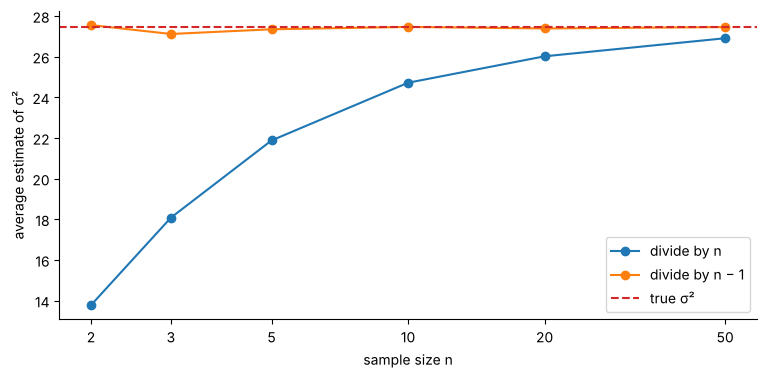

In [31]:
sizes = [2, 3, 5, 10, 20, 50]
avg_n, avg_n1 = [], []
for n in sizes:
    s = rng.choice(population, size=(20_000, n))
    avg_n.append(s.var(axis=1, ddof=0).mean())
    avg_n1.append(s.var(axis=1, ddof=1).mean())

plt.plot(sizes, avg_n, "o-", label="divide by n")
plt.plot(sizes, avg_n1, "o-", label="divide by n − 1")
plt.axhline(sigma2, color="tab:red", ls="--", label="true σ²")
plt.xscale("log"); plt.minorticks_off(); plt.xticks(sizes, sizes)
plt.xlabel("sample size n"); plt.ylabel("average estimate of σ²"); plt.legend(); plt.show()

### ⚠️ The trap: numpy and pandas have different defaults
| Tool | Default | Divides by |
|---|---|---|
| `np.var`, `np.std` | `ddof=0` | n |
| `pd.Series.var`, `.std`, `df.describe()` | `ddof=1` | n − 1 |

In [32]:
small = pd.Series([2, 4, 4, 5, 7])
print("np.var      :", np.var(small))
print("np.var ddof1:", np.var(small, ddof=1))
print("pandas .var :", small.var())

np.var      : 2.6399999999999997
np.var ddof1: 3.3
pandas .var : 3.3


✅ **Rule:** always write `ddof` explicitly. Data science almost always works with samples → `ddof=1`.

---
## 7 · Distributions with `scipy.stats` 📊 (15')

Every distribution in `scipy.stats` works the same way (it's a class, remember Week 2!):

| Method | Meaning |
|---|---|
| `.pmf(k)` / `.pdf(x)` | bar height (discrete) / density (continuous) |
| `.cdf(x)` | P(X ≤ x) |
| `.sf(x)` | P(X > x) = 1 − cdf |
| `.ppf(q)` | the value x with P(X ≤ x) = q (percentiles) |
| `.rvs(size)` | random samples |
| `.mean()`, `.var()`, `.std()` | theoretical mean, variance, std |

### 7.1 Bernoulli → Binomial: hitting the step goal
One user-day = one yes/no trial → **Bernoulli(p)**. We estimate p from the data.

In [33]:
p_goal = goal.mean()
print(f"p = P(goal) ≈ {p_goal:.3f}")

day = stats.bernoulli(p_goal)
print("Bernoulli mean:", round(day.mean(), 3), " variance p(1−p):", round(day.var(), 3))

p = P(goal) ≈ 0.259
Bernoulli mean: 0.259  variance p(1−p): 0.192


A team of **20 users**: how many hit the goal on a given day? If users are independent, X ~ **Binomial(n = 20, p)**.
Let's compare the theory with real days from our data.

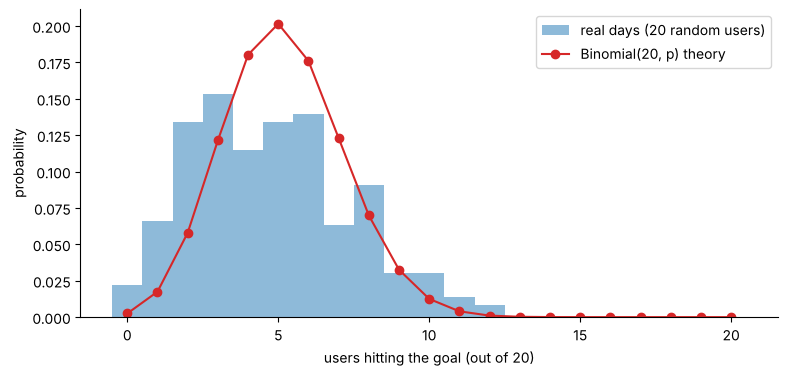

theory: E[X] = 5.18, σ = 1.96  |  data: mean = 4.75, std = 2.61


In [34]:
X = stats.binom(n=20, p=p_goal)
k = np.arange(0, 21)

# real data: for each date, pick 20 random users and count how many hit the goal
real_counts = (data.groupby("date")["goal"]
                   .apply(lambda g: g.sample(20, random_state=0).sum()))

plt.hist(real_counts, bins=np.arange(-0.5, 21), density=True, alpha=0.5, label="real days (20 random users)")
plt.plot(k, X.pmf(k), "o-", color="tab:red", label="Binomial(20, p) theory")
plt.xlabel("users hitting the goal (out of 20)"); plt.ylabel("probability"); plt.legend(); plt.show()

print(f"theory: E[X] = {X.mean():.2f}, σ = {X.std():.2f}  |  data: mean = {real_counts.mean():.2f}, std = {real_counts.std():.2f}")

📌 **The model is close but not perfect:** the real counts are **more spread out** than the Binomial. Why? The Binomial assumes every user-day has the **same p** and users are **independent**. In reality, on a sunny Sunday *everybody* walks more and on a rainy Monday *everybody* walks less, so the counts on the same day move together. Checking assumptions is part of the job!

🧑‍💻 **Code with me:** P(exactly 5 hit the goal), P(at most 3), P(more than 8).

In [35]:
print("P(X = 5)  =", round(X.pmf(5), 4))
print("P(X <= 3) =", round(X.cdf(3), 4))
print("P(X > 8)  =", round(X.sf(8), 4))

P(X = 5)  = 0.2015
P(X <= 3) = 0.1992
P(X > 8)  = 0.0503


### 7.2 Poisson: counts per interval
Suppose an app sends on average λ = 3 notifications per hour. Number per hour ~ **Poisson(3)**. Mean **and** variance are both λ.

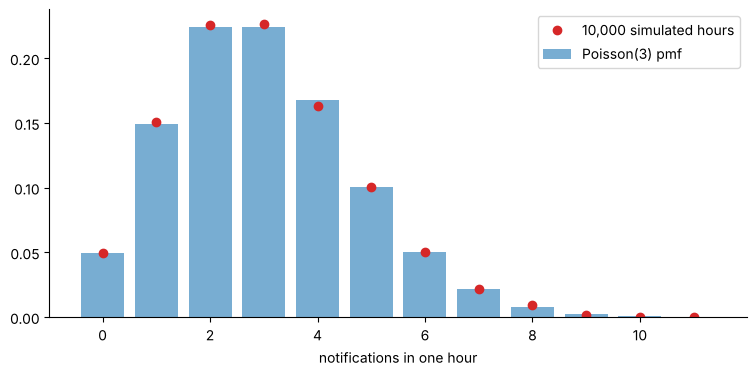

P(no notification in an hour) = 0.05 | mean = 3.0 | var = 3.0


In [36]:
N = stats.poisson(mu=3)
k = np.arange(0, 12)
sim = N.rvs(size=10_000, random_state=1)

plt.bar(k, N.pmf(k), alpha=0.6, label="Poisson(3) pmf")
plt.plot(k, [np.mean(sim == i) for i in k], "o", color="tab:red", label="10,000 simulated hours")
plt.xlabel("notifications in one hour"); plt.legend(); plt.show()
print("P(no notification in an hour) =", round(N.pmf(0), 3), "| mean =", N.mean(), "| var =", N.var())

### 7.3 Normal: resting heart rate
Many biological measurements look like a bell. We **fit** a Normal by plugging in the sample mean and std, and compare with the histogram.

Normal(μ = 71.7, σ = 5.2)


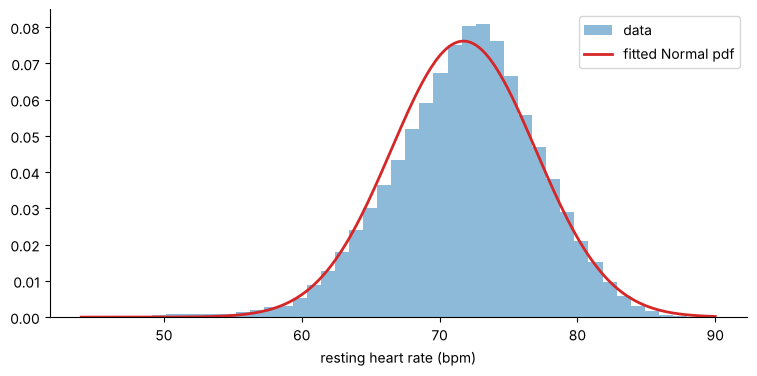

In [37]:
hr = data["resting_hr"]
mu_hr, sd_hr = hr.mean(), hr.std(ddof=1)
H = stats.norm(loc=mu_hr, scale=sd_hr)
print(f"Normal(μ = {mu_hr:.1f}, σ = {sd_hr:.1f})")

grid = np.linspace(hr.min(), hr.max(), 300)
plt.hist(hr, bins=45, density=True, alpha=0.5, label="data")   # density=True → total area = 1, like a pdf
plt.plot(grid, H.pdf(grid), color="tab:red", lw=2, label="fitted Normal pdf")
plt.xlabel("resting heart rate (bpm)"); plt.legend(); plt.show()

🧑‍💻 **Code with me:** check the **68–95–99.7 rule** on the data, and compare to the Normal model.

In [38]:
for k_sd in [1, 2, 3]:
    inside_data = hr.between(mu_hr - k_sd * sd_hr, mu_hr + k_sd * sd_hr).mean()
    inside_model = H.cdf(mu_hr + k_sd * sd_hr) - H.cdf(mu_hr - k_sd * sd_hr)
    print(f"within ±{k_sd}σ: data {inside_data:.3f} | Normal {inside_model:.3f}")

within ±1σ: data 0.671 | Normal 0.683
within ±2σ: data 0.958 | Normal 0.954
within ±3σ: data 0.993 | Normal 0.997


In [39]:
print("P(HR > 80) model:", round(H.sf(80), 4), "| data:", round((hr > 80).mean(), 4))
print("95th percentile model:", round(H.ppf(0.95), 1), "| data:", hr.quantile(0.95))

P(HR > 80) model: 0.0572 | data: 0.0374
95th percentile model: 80.3 | data: 80.0


📌 Close, but not perfect: the data has a longer **left** tail (very fit people with a low resting HR) and fewer very high values than the Normal predicts (3.7% vs 5.7% above 80 bpm). A model is a **useful approximation**: always check it against the data.

> 🧠 For a continuous variable, P(HR = exactly 72.000…) = 0. Probabilities are **areas**: `H.cdf(b) − H.cdf(a)`.

### 7.4 Exponential and Uniform (quick look)

In [40]:
wait = stats.expon(scale=1 / 3)        # waiting time (hours) between notifications when λ = 3 per hour → mean 1/3 h = 20 min
print(f"mean wait = {wait.mean() * 60:.0f} min | P(wait > 1 hour) = {wait.sf(1):.3f}")

u = stats.uniform(loc=0, scale=1)      # Uniform(0, 1): loc = start, scale = width
print("Uniform(0,1): mean", u.mean(), " var", round(u.var(), 4), "(theory 1/12 =", round(1 / 12, 4), ")")

mean wait = 20 min | P(wait > 1 hour) = 0.050
Uniform(0,1): mean 0.5  var 0.0833 (theory 1/12 = 0.0833 )


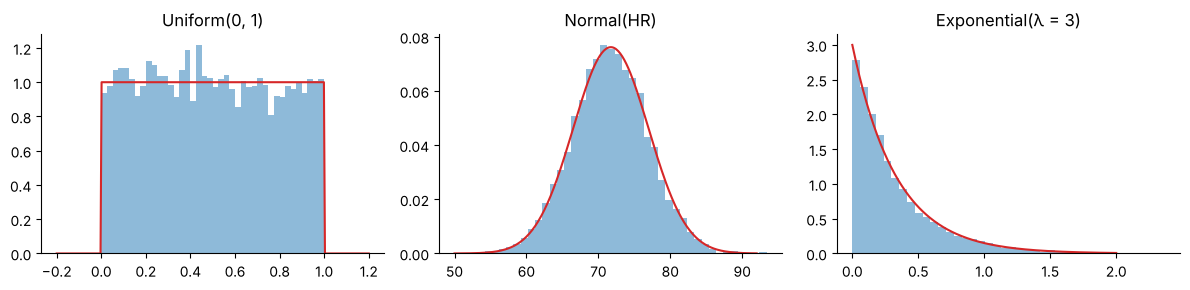

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, dist, xs) in zip(axes, [("Uniform(0, 1)", u, np.linspace(-0.2, 1.2, 300)),
                                        ("Normal(HR)", H, np.linspace(50, 92, 300)),
                                        ("Exponential(λ = 3)", wait, np.linspace(0, 2, 300))]):
    ax.hist(dist.rvs(size=5_000, random_state=2), bins=40, density=True, alpha=0.5)
    ax.plot(xs, dist.pdf(xs), color="tab:red")
    ax.set_title(name)
plt.tight_layout(); plt.show()

---
## 8 · Final challenge 🏁 (6')

✋ **Your turn** (the exercise from the slides): a team of **20 users**, each hits the goal with probability **0.3**, independently. X = number who hit it.
1. Which distribution? Compute E[X], Var(X) and σ with `scipy.stats`.
2. P(X = 0)?
3. Check your answer to 2 with a simulation of 100,000 days.
4. Resting HR ~ Normal(62, 8): which share of users is above 78 bpm?

In [42]:
X = stats.binom(n=20, p=0.3)
print("1)", "E =", X.mean(), "| Var =", round(X.var(), 2), "| σ =", round(X.std(), 2))
print("2)", "P(X = 0) =", round(X.pmf(0), 5))

days = rng.binomial(n=20, p=0.3, size=100_000)
print("3)", "simulated P(X = 0) ≈", (days == 0).mean())

print("4)", "P(HR > 78) =", round(stats.norm(62, 8).sf(78), 4))

1) E = 6.0 | Var = 4.2 | σ = 2.05
2) P(X = 0) = 0.0008
3) simulated P(X = 0) ≈ 0.00093
4) P(HR > 78) = 0.0228


## 🧭 Recap

| Idea | Python |
|---|---|
| probability ≈ long-run frequency | `mask.mean()` |
| and / or / not | `A & B`, `A \| B`, `~A` |
| conditional probability | `A[B].mean()` or `pd.crosstab(..., normalize="index")` |
| Bayes | `sens * prior / (sens * prior + fpr * (1 - prior))` |
| expected value, variance | `np.sum(x * p)`, `np.sum((x - mu)**2 * p)` |
| sample variance | `ddof=1` (pandas default), numpy default is `ddof=0` |
| distributions | `stats.binom`, `stats.poisson`, `stats.norm`, `stats.expon`, `stats.uniform` + `.pmf/.pdf/.cdf/.sf/.ppf/.rvs` |

🧪 **Saturday labs:** probability intro · discrete & continuous distributions.
🔜 **Thursday:** samples vs populations, the central limit theorem, confidence intervals and hypothesis tests. Today's simulations are exactly how we will *see* the CLT.